# Notebook Piloto — Benchmark de Conteo (Parte 1: Evaluación)

**Modelo:** InternVL2-1B — el modelo más compacto de la familia InternVL2.
**Benchmark:** TallyQA — formato más simple (imagen + pregunta en texto + respuesta entera).

**Supuesto de partida:** empezamos con esta combinación porque es la más rápida de iterar. Una vez validado el pipeline completo (carga → muestreo → inferencia → métricas → guardado), se replica para CAPTURe y para los otros 4 modelos, cambiando únicamente la celda de **Configuración**.

**Importante:** este notebook usa el `test.json` **oficial** de TallyQA (no el `train.json` del notebook exploratorio anterior), porque es el que efectivamente trae el campo `issimple` que necesitamos para separar conteo simple vs. complejo.

**Requisitos de entorno:** activar GPU en Colab → `Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU` (alcanza con una T4 gratuita).

**Alcance de este notebook:** solo la Parte 1 (evaluación / métricas). La Parte 2 (explicabilidad con grounding) se aborda en un notebook separado más adelante.


## 1. Instalación de dependencias

In [1]:
# IMPORTANTE: se fija transformers==4.46.2 (última release de la serie 4.x).
# transformers>=5.0 tiene un bug de compatibilidad conocido con modelos que usan
# trust_remote_code (Moondream2, Molmo, y varios otros) al inicializar el tie de pesos:
# https://github.com/huggingface/transformers/issues/43883
!pip install -q "transformers==4.46.2" "huggingface_hub>=0.23" accelerate einops timm pillow psutil sentencepiece
print("Dependencias instaladas.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 63.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Dependencias instaladas.


In [2]:
import transformers
print(f"Versión de transformers activa: {transformers.__version__}")

if not transformers.__version__.startswith("4."):
    raise RuntimeError(
        "transformers quedó en una version >= 5.x a pesar del pip install de la celda anterior.\n"
        "Esto pasa cuando Colab ya tenia una version distinta cargada en memoria ANTES de correr "
        "esta celda (el pip install no afecta un modulo que Python ya importo en esta sesion).\n\n"
        "SOLUCION: Entorno de ejecucion > Reiniciar sesion, y luego "
        "Entorno de ejecucion > Ejecutar todo, para que la version fijada (4.46.2) quede activa "
        "desde el principio de una sesion limpia."
    )
print("Version compatible con el codigo de Moondream2 (trust_remote_code). Continuando...")


Versión de transformers activa: 4.46.2
Version compatible con el codigo de Moondream2 (trust_remote_code). Continuando...


## 2. Configuración de la corrida

Estos son los únicos parámetros que hay que tocar para reutilizar este notebook con otro modelo o benchmark.


In [3]:
MODEL_ID = "OpenGVLab/InternVL2-1B"
MODEL_REVISION = "main"  # fijar una revisión concreta ayuda a la reproducibilidad;
                                 # revisar la ficha del modelo en HuggingFace por si hay una más reciente

BENCHMARK_NAME = "TallyQA"

SAMPLE_SIZE = 300      # tamaño de la muestra piloto (subir una vez validado el pipeline)
RANDOM_SEED = 42

# Buckets de conteo (ground truth) para el desglose de error por magnitud.
# Ajustados a la distribución real de TallyQA-test (rango 0-15, muy concentrado en valores bajos).
COUNT_BUCKETS = [(0, 2), (3, 5), (6, 15)]

TIMEOUT_SEGUNDOS = 30
# Limite duro por pregunta. Si una consulta al modelo supera esto, se registra como
# "timeout" y se sigue con la siguiente -- no se pierde la corrida completa por un caso lento.
# Si terminas con muchos timeouts, es la señal de ir a revisar la celda de diagnostico de GPU,
# no de subir este numero indefinidamente.

PROMPT_SUFFIX = " Respond with only the integer number, no other words."
# Moondream2 a veces responde en palabras ('There is one person...') en vez de un digito.
# Se agrega este sufijo a cada pregunta para forzar una respuesta corta y numerica,
# tanto para facilitar el parseo como para que la comparacion entre modelos sea mas justa
# (todos reciben la misma instruccion de formato).

OUTPUT_TXT_PATH = f"/content/resultados_{BENCHMARK_NAME}_{MODEL_ID.split('/')[-1]}.txt"
OUTPUT_CSV_PATH = f"/content/detalle_{BENCHMARK_NAME}_{MODEL_ID.split('/')[-1]}.csv"

print(f"Modelo:      {MODEL_ID} (revision={MODEL_REVISION})")
print(f"Benchmark:   {BENCHMARK_NAME}")
print(f"Muestra:     {SAMPLE_SIZE} preguntas (semilla={RANDOM_SEED})")
print(f"Salida .txt: {OUTPUT_TXT_PATH}")


Modelo:      OpenGVLab/InternVL2-1B (revision=main)
Benchmark:   TallyQA
Muestra:     300 preguntas (semilla=42)
Salida .txt: /content/resultados_TallyQA_InternVL2-1B.txt


## 3. Cargar el modelo

In [4]:
import torch
from transformers import AutoTokenizer, AutoModel
import torchvision.transforms as T
from torchvision.transforms.functional import InterpolationMode

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo detectado: {device}")
if device == "cpu":
    print("ADVERTENCIA: sin GPU. La inferencia será muy lenta.")

if device == "cuda":
    torch.cuda.reset_peak_memory_stats()

# ── Preprocesamiento de imagen (específico de InternVL2) ──────────────────
# InternVL2 no usa AutoProcessor estándar — necesita su propio pipeline
# de normalización y división dinámica de la imagen en tiles.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

def _build_transform(input_size=448):
    return T.Compose([
        T.Lambda(lambda img: img.convert("RGB") if img.mode != "RGB" else img),
        T.Resize((input_size, input_size), interpolation=InterpolationMode.BICUBIC),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def _dynamic_preprocess(image, image_size=448, min_num=1, max_num=6, use_thumbnail=True):
    """Divide la imagen en tiles según su aspecto para que el modelo vea más detalle."""
    w, h = image.size
    ratio = w / h
    ratios = {(i, j) for n in range(min_num, max_num + 1)
              for i in range(1, n + 1) for j in range(1, n + 1)
              if min_num <= i * j <= max_num}
    best = min(ratios, key=lambda r: abs(r[0] / r[1] - ratio))
    tw, th = image_size * best[0], image_size * best[1]
    img_resized = image.resize((tw, th))
    tiles = []
    for idx in range(best[0] * best[1]):
        col, row = idx % best[0], idx // best[0]
        box = (col * image_size, row * image_size,
               (col + 1) * image_size, (row + 1) * image_size)
        tiles.append(img_resized.crop(box))
    if use_thumbnail and len(tiles) > 1:
        tiles.append(image.resize((image_size, image_size)))
    return tiles

def preparar_imagen_internvl(imagen_pil, input_size=448, max_num=6):
    """Convierte PIL.Image a tensor listo para InternVL2."""
    transform = _build_transform(input_size)
    tiles = _dynamic_preprocess(imagen_pil, image_size=input_size,
                                 use_thumbnail=True, max_num=max_num)
    pixel_values = torch.stack([transform(t) for t in tiles])
    return pixel_values
# ─────────────────────────────────────────────────────────────────────────

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, trust_remote_code=True
)
print(f"Tokenizer cargado: {type(tokenizer).__name__} → {tokenizer}")  # ← AGREGAR

model = AutoModel.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True,
    trust_remote_code=True,
).eval()

if device == "cuda":
    model = model.cuda()

vram_after_load_mb = (torch.cuda.max_memory_allocated() / 1024**2) if device == "cuda" else 0
print(f"Modelo cargado. VRAM tras la carga: {vram_after_load_mb:.1f} MB")
# Silencia el warning repetitivo de pad_token_id en cada llamada a generate()
if model.generation_config.pad_token_id is None:
    model.generation_config.pad_token_id = model.generation_config.eos_token_id


# ── Interfaz común ──────────────────────────────────────────────
GENERATION_CONFIG = dict(max_new_tokens=32, do_sample=False)


def predecir(imagen, pregunta):
    """Recibe PIL.Image y str, devuelve str (respuesta cruda del modelo)."""
    pixel_values = preparar_imagen_internvl(imagen).to(torch.bfloat16).to(device)
    return model.chat(tokenizer, pixel_values, pregunta, GENERATION_CONFIG, history=None, return_history=False)
# ────────────────────────────────────────────────────────────────

print("Interfaz predecir() lista.")


Dispositivo detectado: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/265 [00:00<?, ?B/s]

... (9 outputs left out)

FlashAttention2 is not installed.


model.safetensors:   0%|          | 0.00/1.88G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/117 [00:00<?, ?B/s]

Modelo cargado. VRAM tras la carga: 1800.1 MB
Interfaz predecir() lista.


### Diagnóstico rápido de GPU

Antes de correr las 50 preguntas conviene confirmar que el modelo realmente quedó en GPU. Si `Dispositivo del modelo` da `cpu` aquí, esa es la causa de una inferencia de minutos por pregunta en vez de segundos — hay que reiniciar la sesión y confirmar `Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU (T4)` antes de seguir.

In [5]:
print("torch.cuda.is_available():", torch.cuda.is_available())
print("Dispositivo del modelo:", next(model.parameters()).device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
!nvidia-smi --query-gpu=name,memory.used,memory.total,utilization.gpu --format=csv 2>/dev/null || echo "nvidia-smi no disponible (sin GPU asignada)"


torch.cuda.is_available(): True
Dispositivo del modelo: cuda:0
GPU: Tesla T4
name, memory.used [MiB], memory.total [MiB], utilization.gpu [%]
Tesla T4, 1977 MiB, 15360 MiB, 29 %


## 4. Descargar TallyQA (test.json oficial)

Fuente: [manoja328/tallyqa](https://github.com/manoja328/tallyqa) — repositorio oficial citado en el paper AAAI 2019.


In [6]:
import urllib.request, zipfile, os, json

TALLYQA_URL = "https://github.com/manoja328/tallyqa/blob/master/tallyqa.zip?raw=true"
ZIP_PATH = "/content/tallyqa.zip"
JSON_PATH = "/content/test.json"

if not os.path.exists(JSON_PATH):
    print("Descargando TallyQA (test.json)...")
    urllib.request.urlretrieve(TALLYQA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extract("test.json", "/content")
    print("Descarga completa.")
else:
    print("test.json ya existe localmente, se omite la descarga.")

with open(JSON_PATH, encoding="utf-8") as f:
    tallyqa_test = json.load(f)

print(f"\nTotal de preguntas en test.json: {len(tallyqa_test)}")
print("Ejemplo de entrada:")
print(json.dumps(tallyqa_test[0], indent=2, ensure_ascii=False))

has_issimple = all("issimple" in d for d in tallyqa_test[:200])
print(f"\n¿Campo 'issimple' presente en las primeras 200 entradas?: {has_issimple}")


Descargando TallyQA (test.json)...
Descarga completa.

Total de preguntas en test.json: 38589
Ejemplo de entrada:
{
  "image": "VG_100K_2/1.jpg",
  "answer": 2,
  "data_source": "imported_genome",
  "question": "How many people are there?",
  "image_id": 90000001,
  "question_id": 30092456,
  "issimple": true
}

¿Campo 'issimple' presente en las primeras 200 entradas?: True


## 5. Muestreo estratificado por `issimple`

Se preserva la proporción real simple/compleja del dataset completo, no un 50/50 arbitrario.


In [7]:
import random
from collections import Counter

random.seed(RANDOM_SEED)

simples = [d for d in tallyqa_test if d["issimple"]]
complejas = [d for d in tallyqa_test if not d["issimple"]]

prop_simple = len(simples) / len(tallyqa_test)
n_simple = round(SAMPLE_SIZE * prop_simple)
n_complex = SAMPLE_SIZE - n_simple

muestra = (
    random.sample(simples, min(n_simple, len(simples)))
    + random.sample(complejas, min(n_complex, len(complejas)))
)
random.shuffle(muestra)

print(f"Proporción real en test.json -> simple: {prop_simple:.1%} | compleja: {1-prop_simple:.1%}")
print(f"Muestra construida: {len(muestra)} preguntas ({n_simple} simples, {n_complex} complejas)")
print(f"Distribución de data_source en la muestra: {dict(Counter(d['data_source'] for d in muestra))}")


Proporción real en test.json -> simple: 59.6% | compleja: 40.4%
Muestra construida: 300 preguntas (179 simples, 121 complejas)
Distribución de data_source en la muestra: {'amt': 121, 'imported_genome': 179}


## 6. Función para descargar imágenes (COCO / Visual Genome)

TallyQA reutiliza imágenes de estos dos datasets según el prefijo de la ruta.


Imagen de prueba cargada correctamente: tamaño (500, 307)
Pregunta: How many zebras are in the center of this image?  |  Respuesta esperada: 2


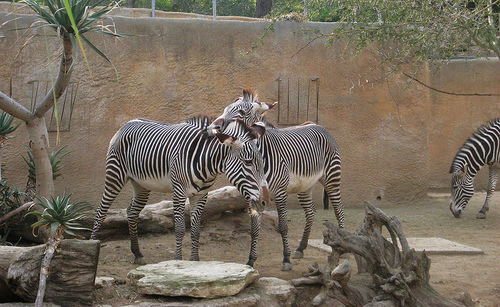

In [8]:
import requests
from PIL import Image
from io import BytesIO
from IPython.display import display

def obtener_imagen(image_path, timeout=10):
    if image_path.startswith(("train2014/", "val2014/")):
        url = f"http://images.cocodataset.org/{image_path}"
    elif image_path.startswith(("VG_100K/", "VG_100K_2/")):
        url = f"https://cs.stanford.edu/people/rak248/{image_path}"
    else:
        raise ValueError(f"Formato de ruta de imagen desconocido: {image_path}")
    resp = requests.get(url, timeout=timeout)
    resp.raise_for_status()
    return Image.open(BytesIO(resp.content)).convert("RGB")

# Prueba rápida con la primera pregunta de la muestra
_img_prueba = obtener_imagen(muestra[0]["image"])
print(f"Imagen de prueba cargada correctamente: tamaño {_img_prueba.size}")
print(f"Pregunta: {muestra[0]['question']}  |  Respuesta esperada: {muestra[0]['answer']}")
display(_img_prueba)


## 7. Loop de inferencia

Por cada pregunta: descarga de imagen → consulta al modelo → parseo de la respuesta a entero → registro de tiempo.

*Nota: `model.query()` se llama aquí con `reasoning=False` (default) para mantener el pipeline de accuracy simple. El modo `reasoning=True` expone puntos de grounding en el razonamiento — eso se explora en el notebook de la Parte 2 (explicabilidad), no acá.*


In [9]:
import re, time, concurrent.futures

NUMEROS_EN_PALABRAS = {
    "zero": 0, "none": 0, "no": 0, "one": 1, "two": 2, "three": 3, "four": 4,
    "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10,
    "eleven": 11, "twelve": 12, "thirteen": 13, "fourteen": 14, "fifteen": 15,
    "sixteen": 16, "seventeen": 17, "eighteen": 18, "nineteen": 19, "twenty": 20,
}

def extraer_entero(texto):
    """Extrae el conteo de la respuesta en texto libre del modelo.
    Primero busca un digito; si no hay, busca un numero escrito en palabras
    (ej. Moondream2 a veces responde 'There is one person...' en vez de '1').
    Devuelve None solo si de verdad no se encuentra nada interpretable (parse fail real)."""
    match = re.search(r"-?\d+", texto)
    if match:
        return int(match.group())
    texto_limpio = re.sub(r"[^\w\s]", " ", texto.lower())
    for palabra, valor in NUMEROS_EN_PALABRAS.items():
        if re.search(rf"\b{palabra}\b", texto_limpio):
            return valor
    return None


def query_con_timeout(imagen, pregunta, timeout_seg):
    """Corre model.query en un hilo aparte con limite de tiempo.

    Importante -- limitacion conocida de este approach: si se cumple el timeout,
    no se puede matar el hilo de forma segura (Python no lo permite para llamadas
    a C/CUDA en curso). El hilo sigue corriendo en segundo plano hasta que el
    modelo termine por su cuenta, consumiendo GPU/CPU mientras tanto. Es un
    compromiso aceptable para un piloto: el loop principal no se bloquea, pero
    si hay MUCHOS timeouts seguidos, probablemente haya varias llamadas "zombie"
    compitiendo por la GPU al mismo tiempo -- en ese caso, mejor parar y revisar
    el diagnostico de GPU en vez de seguir subiendo el timeout.
    """
    executor = concurrent.futures.ThreadPoolExecutor(max_workers=1)
    future = executor.submit(predecir, imagen, pregunta)
    try:
        resultado = future.result(timeout=timeout_seg)
        executor.shutdown(wait=False)
        return resultado, False
    except concurrent.futures.TimeoutError:
        executor.shutdown(wait=False)
        return None, True


resultados = []
fallos_descarga = 0
n_timeouts = 0

print(f"Iniciando inferencia sobre {len(muestra)} preguntas (timeout={TIMEOUT_SEGUNDOS}s)...\n")

for i, item in enumerate(muestra):
    try:
        img = obtener_imagen(item["image"])
    except Exception as e:
        fallos_descarga += 1
        print(f"[{i+1}/{len(muestra)}] Error descargando imagen ({item['image']}): {e}")
        continue

    pregunta_modelo = item["question"] + PROMPT_SUFFIX

    t0 = time.time()
    respuesta_cruda, timed_out = query_con_timeout(img, pregunta_modelo, TIMEOUT_SEGUNDOS)
    t1 = time.time()

    if timed_out:
        n_timeouts += 1
        pred = None
        parse_fail = False  # no es que no se pudo parsear -- ni siquiera hubo respuesta a tiempo
    else:
        pred = extraer_entero(respuesta_cruda)
        parse_fail = pred is None

    resultados.append({
        "question_id": item["question_id"],
        "pregunta": item["question"],
        "ground_truth": item["answer"],
        "issimple": item["issimple"],
        "data_source": item["data_source"],
        "respuesta_cruda": respuesta_cruda,
        "prediccion": pred,
        "parse_fail": parse_fail,
        "timeout": timed_out,
        "error_abs": abs(pred - item["answer"]) if (pred is not None) else None,
        "acierto_exacto": (pred == item["answer"]) if (pred is not None) else False,
        "tiempo_seg": t1 - t0,
        "imagen": item["image"],
    })

    if timed_out:
        print(f"[{i+1}/{len(muestra)}] TIMEOUT tras {t1-t0:.1f}s -- se registra y se sigue.")
    elif (i + 1) % 10 == 0 or i == 0:
        print(f"[{i+1}/{len(muestra)}] GT={item['answer']:>3} | Pred={str(pred):>4} | "
              f"'{respuesta_cruda}' | {t1-t0:.2f}s")

print(f"\nInferencia terminada: {len(resultados)} preguntas procesadas, "
      f"{fallos_descarga} fallos de descarga de imagen, {n_timeouts} timeouts.")


Iniciando inferencia sobre 300 preguntas (timeout=30s)...



Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[1/300] GT=  2 | Pred=   1 | '1' | 3.80s


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[10/300] GT=  5 | Pred=   3 | '3' | 2.96s


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


... (53 outputs left out)

Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[290/300] GT=  1 | Pred=   1 | '1' | 3.42s


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[300/300] GT=  1 | Pred=   1 | '1' | 3.47s

Inferencia terminada: 300 preguntas procesadas, 0 fallos de descarga de imagen, 0 timeouts.


## 8. Métricas agregadas

In [10]:
import pandas as pd
import psutil

df = pd.DataFrame(resultados)

vram_peak_mb = (torch.cuda.max_memory_allocated() / 1024**2) if device == "cuda" else 0
ram_peak_mb = psutil.Process().memory_info().rss / 1024**2

n_total = len(df)
n_timeouts = int(df["timeout"].sum())
n_parse_fail = int(df["parse_fail"].sum())
timeout_rate = n_timeouts / n_total if n_total else float("nan")
parse_fail_rate = n_parse_fail / n_total if n_total else float("nan")

# Validos para accuracy/MAE: ni timeout ni parse fail
df_validos = df[(~df["parse_fail"]) & (~df["timeout"])].copy()

# Tiempos: se excluyen los timeouts porque su "tiempo_seg" es artificial (= TIMEOUT_SEGUNDOS,
# el limite impuesto, no el tiempo real que habria tardado el modelo)
df_tiempos = df[~df["timeout"]]

accuracy = df_validos["acierto_exacto"].mean()
mae = df_validos["error_abs"].mean()
varianza_error = df_validos["error_abs"].var()
tiempo_medio = df_tiempos["tiempo_seg"].mean()
tiempo_std = df_tiempos["tiempo_seg"].std()

print("=" * 60)
print(f"RESULTADOS — {BENCHMARK_NAME} — {MODEL_ID}")
print("=" * 60)
print(f"Preguntas evaluadas:      {n_total}")
print(f"Timeout rate:             {timeout_rate:.1%}  ({n_timeouts}/{n_total})  [limite={TIMEOUT_SEGUNDOS}s]")
print(f"Parse fail rate:          {parse_fail_rate:.1%}  ({n_parse_fail}/{n_total})")
print(f"Exactitud (exact match):  {accuracy:.1%}  (sobre {len(df_validos)} preguntas validas)")
print(f"MAE:                      {mae:.3f}")
print(f"Varianza del error:       {varianza_error:.3f}")
print(f"Tiempo medio/pregunta:    {tiempo_medio:.2f}s (± {tiempo_std:.2f}s)  [excluye timeouts]")
print(f"VRAM pico:                {vram_peak_mb:.1f} MB")
print(f"RAM pico (proceso):       {ram_peak_mb:.1f} MB")

if timeout_rate > 0.2:
    print("\nADVERTENCIA: timeout rate > 20%. Antes de subir TIMEOUT_SEGUNDOS, revisa la celda de")
    print("diagnostico de GPU -- es mas probable que el modelo este en CPU que que el limite este mal puesto.")

print("\n--- Desglose por tipo de pregunta (simple vs. compleja) ---")
for es_simple, grupo in df_validos.groupby("issimple"):
    etiqueta = "Simple" if es_simple else "Compleja"
    print(f"{etiqueta:10s}: n={len(grupo):3d} | accuracy={grupo['acierto_exacto'].mean():.1%} | "
          f"MAE={grupo['error_abs'].mean():.3f}")

def asignar_bucket(gt):
    for lo, hi in COUNT_BUCKETS:
        if lo <= gt <= hi:
            return f"{lo}-{hi}"
    return "fuera_de_rango"

df_validos["bucket"] = df_validos["ground_truth"].apply(asignar_bucket)

print("\n--- Desglose por rango de conteo real (ground truth) ---")
for bucket, grupo in df_validos.groupby("bucket"):
    print(f"Rango {bucket:8s}: n={len(grupo):3d} | accuracy={grupo['acierto_exacto'].mean():.1%} | "
          f"MAE={grupo['error_abs'].mean():.3f}")


RESULTADOS — TallyQA — OpenGVLab/InternVL2-1B
Preguntas evaluadas:      300
Timeout rate:             0.0%  (0/300)  [limite=30s]
Parse fail rate:          0.3%  (1/300)
Exactitud (exact match):  72.9%  (sobre 299 preguntas validas)
MAE:                      0.368
Varianza del error:       0.569
Tiempo medio/pregunta:    3.14s (± 0.79s)  [excluye timeouts]
VRAM pico:                2350.2 MB
RAM pico (proceso):       2951.9 MB

--- Desglose por tipo de pregunta (simple vs. compleja) ---
Compleja  : n=120 | accuracy=64.2% | MAE=0.467
Simple    : n=179 | accuracy=78.8% | MAE=0.302

--- Desglose por rango de conteo real (ground truth) ---
Rango 0-2     : n=259 | accuracy=78.4% | MAE=0.259
Rango 3-5     : n= 31 | accuracy=32.3% | MAE=0.871
Rango 6-15    : n=  9 | accuracy=55.6% | MAE=1.778


## 9. Gráficos

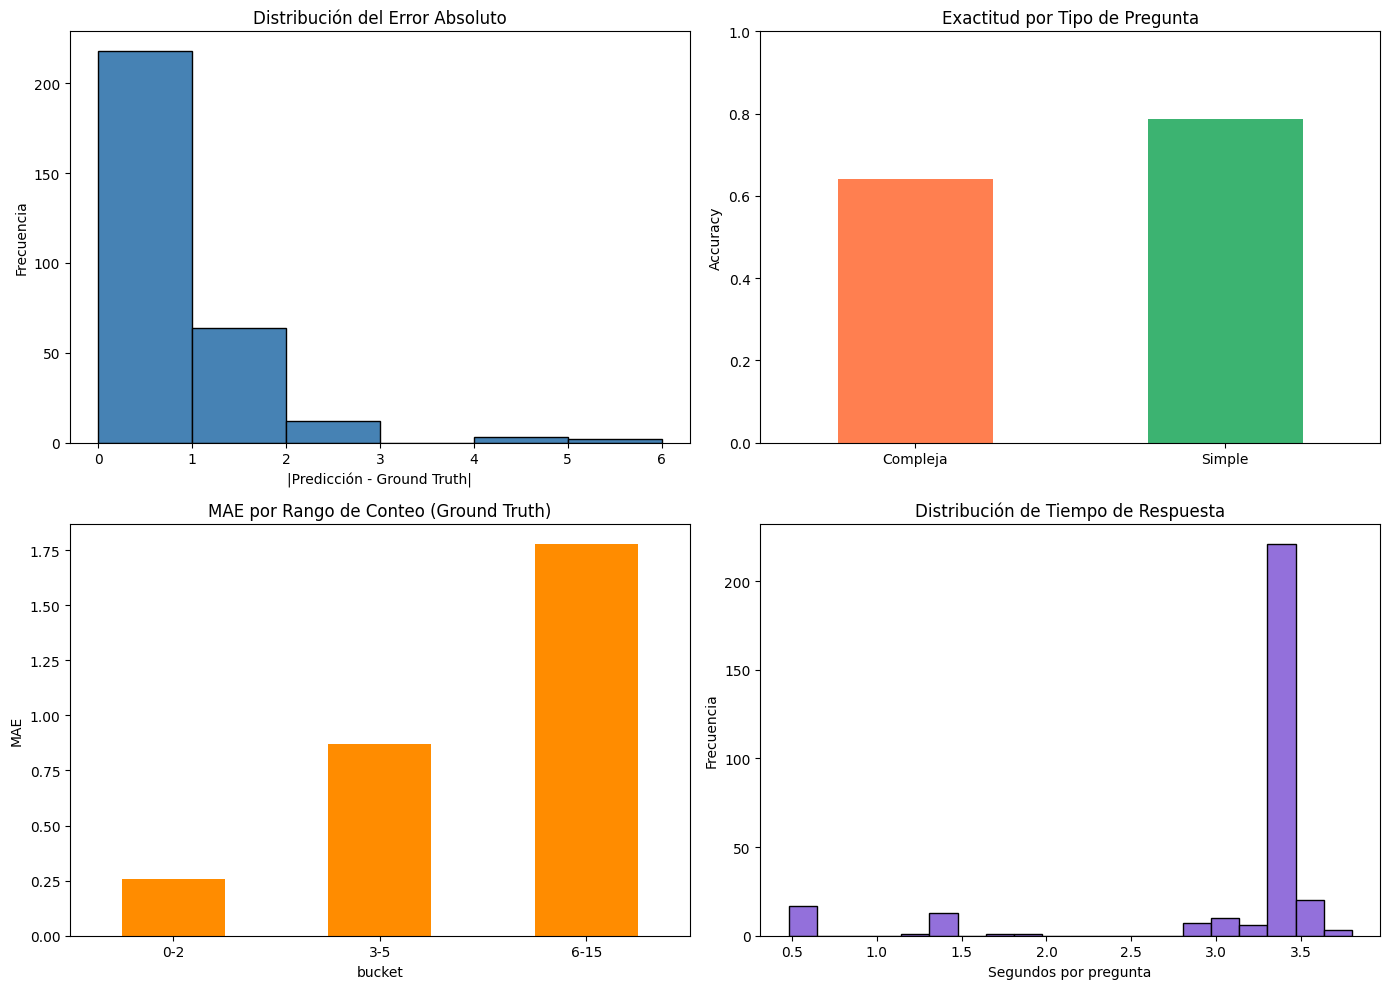

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribución del error absoluto
max_err = int(df_validos["error_abs"].max()) if len(df_validos) else 0
axes[0, 0].hist(df_validos["error_abs"], bins=range(0, max_err + 2), color="steelblue", edgecolor="black")
axes[0, 0].set_title("Distribución del Error Absoluto")
axes[0, 0].set_xlabel("|Predicción - Ground Truth|")
axes[0, 0].set_ylabel("Frecuencia")

# 2. Exactitud por tipo de pregunta
resumen_tipo = df_validos.groupby("issimple")["acierto_exacto"].mean()
resumen_tipo.index = ["Compleja" if not x else "Simple" for x in resumen_tipo.index]
resumen_tipo.plot(kind="bar", ax=axes[0, 1], color=["coral", "mediumseagreen"])
axes[0, 1].set_title("Exactitud por Tipo de Pregunta")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].tick_params(axis="x", rotation=0)

# 3. MAE por rango de conteo
resumen_bucket = df_validos.groupby("bucket")["error_abs"].mean()
resumen_bucket.plot(kind="bar", ax=axes[1, 0], color="darkorange")
axes[1, 0].set_title("MAE por Rango de Conteo (Ground Truth)")
axes[1, 0].set_ylabel("MAE")
axes[1, 0].tick_params(axis="x", rotation=0)

# 4. Distribución de tiempos de respuesta
axes[1, 1].hist(df_tiempos["tiempo_seg"], bins=20, color="mediumpurple", edgecolor="black")  # excluye timeouts
axes[1, 1].set_title("Distribución de Tiempo de Respuesta")
axes[1, 1].set_xlabel("Segundos por pregunta")
axes[1, 1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.savefig("/content/graficos_resumen.png", dpi=120)
plt.show()


## 10. Guardar resultados en `.txt` (para consolidar después)

Este archivo es el que se descarga y se junta con los resultados de los demás modelos/benchmarks más adelante. También se guarda un `.csv` con el detalle pregunta por pregunta, por si se necesita reanalizar sin volver a correr el modelo.


In [12]:
import datetime

with open(OUTPUT_TXT_PATH, "w", encoding="utf-8") as f:
    f.write(f"BENCHMARK: {BENCHMARK_NAME}\n")
    f.write(f"MODELO: {MODEL_ID} (revision={MODEL_REVISION})\n")
    f.write(f"FECHA: {datetime.datetime.now().isoformat()}\n")
    f.write(f"TAMANO_MUESTRA: {n_total}\n")
    f.write(f"SEMILLA: {RANDOM_SEED}\n")
    f.write("-" * 50 + "\n")
    f.write(f"TIMEOUT_RATE: {timeout_rate:.4f}\n")
    f.write(f"PARSE_FAIL_RATE: {parse_fail_rate:.4f}\n")
    f.write(f"ACCURACY_EXACTA: {accuracy:.4f}\n")
    f.write(f"MAE: {mae:.4f}\n")
    f.write(f"VARIANZA_ERROR: {varianza_error:.4f}\n")
    f.write(f"TIEMPO_MEDIO_SEG: {tiempo_medio:.4f}\n")
    f.write(f"TIEMPO_STD_SEG: {tiempo_std:.4f}\n")
    f.write(f"VRAM_PICO_MB: {vram_peak_mb:.2f}\n")
    f.write(f"RAM_PICO_MB: {ram_peak_mb:.2f}\n")
    f.write("-" * 50 + "\n")
    f.write("DESGLOSE_POR_TIPO\n")
    for es_simple, grupo in df_validos.groupby("issimple"):
        etiqueta = "simple" if es_simple else "compleja"
        f.write(f"  {etiqueta}: n={len(grupo)} accuracy={grupo['acierto_exacto'].mean():.4f} "
                f"mae={grupo['error_abs'].mean():.4f}\n")
    f.write("-" * 50 + "\n")
    f.write("DESGLOSE_POR_RANGO_CONTEO\n")
    for bucket, grupo in df_validos.groupby("bucket"):
        f.write(f"  {bucket}: n={len(grupo)} accuracy={grupo['acierto_exacto'].mean():.4f} "
                f"mae={grupo['error_abs'].mean():.4f}\n")
    f.write("-" * 50 + "\n")
    f.write("DETALLE_POR_PREGUNTA (question_id | ground_truth | prediccion | parse_fail | timeout | error_abs | tiempo_seg)\n")
    for _, row in df.iterrows():
        f.write(f"  {row['question_id']} | {row['ground_truth']} | {row['prediccion']} | "
                f"{row['parse_fail']} | {row['timeout']} | {row['error_abs']} | {row['tiempo_seg']:.3f}\n")

print(f"Resultados guardados en: {OUTPUT_TXT_PATH}")

df.to_csv(OUTPUT_CSV_PATH, index=False)
print(f"Detalle completo guardado como CSV en: {OUTPUT_CSV_PATH}")

try:
    from google.colab import files
    files.download(OUTPUT_TXT_PATH)
    files.download(OUTPUT_CSV_PATH)
except ImportError:
    print("No se detectó entorno Colab — descarga los archivos manualmente desde el panel de archivos (ícono de carpeta a la izquierda).")


Resultados guardados en: /content/resultados_TallyQA_InternVL2-1B.txt
Detalle completo guardado como CSV en: /content/detalle_TallyQA_InternVL2-1B.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>